# Wet AMD Lesion Segmentation: Model 2 (Cascaded Two-Stage U-Net)
**Dataset:** AMD-SD (Optical Coherence Tomography Image Dataset for wet AMD Lesions Segmentation)
**Objective:** Construct and train a 2-part cascaded U-Net model:
1. **Stage 1 (UNet 1):** Grayscale OCT input $\to$ Continuous binary foreground probability mask ($512 \times 512$).
2. **Stage 2 (UNet 2):** Binary mask $\to$ Multi-class segmentation mask ($6$ classes, $512 \times 512$).
3. **Deep Supervision:** Joint end-to-end optimization combining **Loss B** (Binary BCE + Dice) and **Loss A** (Multi-class CE + Dice).

In [1]:
import os
import gc
import csv
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Set environment variables for memory management
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"

def seed_everything(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def cleanup_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()

seed_everything(42)
cleanup_memory()

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print(f"Active Compute Device: {device}")

Active Compute Device: mps


## 1. Dataset Pipeline & Color Palette Setup
Reuses the verified `AMDDataset` loader with $(512 \times 512)$ resolution, horizontal flip ($p=0.5$), and rotation ($\pm 10^\circ$). The multi-class ground truth ($0$ to $5$) will be converted on the fly during training into a binary mask for Stage 1 supervision.

In [2]:
# Reference RGB color palette for the 6 target classes in AMD-SD
CLASS_PALETTE_RGB = np.array([
    [0, 0, 0],        # 0: Background
    [255, 0, 0],      # 1: Subretinal Fluid (SRF)
    [0, 255, 0],      # 2: Intraretinal Fluid (IRF)
    [0, 0, 255],      # 3: Pigment Epithelial Detachment (PED)
    [255, 255, 0],    # 4: Subretinal Hyperreflective Material (SHRM)
    [255, 0, 255]     # 5: Ellipsoid Zone (IS/OS)
], dtype=np.int32)

CLASS_NAMES = ["Background", "SRF", "IRF", "PED", "SHRM", "IS/OS"]

class AMDDataset(Dataset):
    def __init__(self, data_root, split="train", target_size=(512, 512), augment=True):
        self.inputs_dir = os.path.join(data_root, split, "inputs")
        self.outputs_dir = os.path.join(data_root, split, "outputs")
        self.target_size = target_size
        self.split = split
        self.augment = augment and (split == "train")

        self.filenames = sorted([
            f for f in os.listdir(self.inputs_dir)
            if f.endswith(('.png', '.jpg', '.jpeg')) and not f.startswith('.')
        ])

    def __len__(self):
        return len(self.filenames)

    def _rgb_to_class(self, mask_rgb):
        mask = np.ascontiguousarray(mask_rgb, dtype=np.int32)
        dists = np.sum((mask[:, :, None, :] - CLASS_PALETTE_RGB[None, None, :, :]) ** 2, axis=-1)
        return np.argmin(dists, axis=-1)

    def _apply_augmentations(self, img, mask):
        if random.random() > 0.5:
            img = cv2.flip(img, 1)
            mask = cv2.flip(mask, 1)

        angle = random.uniform(-10.0, 10.0)
        h, w = img.shape[:2]
        center = (w // 2, h // 2)
        M = cv2.getRotationMatrix2D(center, angle, 1.0)
        img = cv2.warpAffine(img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
        mask = cv2.warpAffine(mask, M, (w, h), flags=cv2.INTER_NEAREST, borderMode=cv2.BORDER_REFLECT_101)
        return img, mask

    def __getitem__(self, idx):
        in_fname = self.filenames[idx]
        img_path = os.path.join(self.inputs_dir, in_fname)
        out_fname = in_fname.replace("_input", "_output") if "_input" in in_fname else in_fname
        mask_path = os.path.join(self.outputs_dir, out_fname)

        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        mask_bgr = cv2.imread(mask_path)
        if img is None or mask_bgr is None:
            raise ValueError(f"Failed to read image/mask pair: {img_path}")

        mask_rgb = cv2.cvtColor(mask_bgr, cv2.COLOR_BGR2RGB)

        img = cv2.resize(img, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_LINEAR)
        mask_rgb = cv2.resize(mask_rgb, (self.target_size[1], self.target_size[0]), interpolation=cv2.INTER_NEAREST)

        mask_labels = self._rgb_to_class(mask_rgb)

        if self.augment:
            img, mask_labels = self._apply_augmentations(img, mask_labels)

        img_tensor = torch.from_numpy(np.ascontiguousarray(img)).unsqueeze(0).float() / 255.0
        mask_tensor = torch.from_numpy(np.ascontiguousarray(mask_labels)).long()

        return img_tensor, mask_tensor

# Setup DataLoaders matching the baseline setup
DATA_DIR = "processed_data"
MICRO_BATCH_SIZE = 2 if device.type == "mps" else 8
ACCUM_STEPS = 4 if device.type == "mps" else 1
VAL_BATCH_SIZE = 2 if device.type == "mps" else 8
NUM_WORKERS = 0 if device.type == "mps" else 4

train_dataset = AMDDataset(DATA_DIR, split="train", target_size=(512, 512), augment=True)
val_dataset = AMDDataset(DATA_DIR, split="val", target_size=(512, 512), augment=False)

train_loader = DataLoader(train_dataset, batch_size=MICRO_BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))
val_loader = DataLoader(val_dataset, batch_size=VAL_BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))

print(f"Loaded {len(train_dataset)} training pairs and {len(val_dataset)} validation pairs.")

Loaded 2346 training pairs and 703 validation pairs.


## 2. Model 2 Architecture: Two-Stage Cascaded U-Net
- **Stage 1 (Binary U-Net):** Input: $1$ channel (OCT B-scan) $\to$ Output: $1$ channel (Binary logits).
- **Sigmoid Activation:** $\sigma(\text{logits}_{\text{bin}})$ produces a continuous probability map $[0.0, 1.0]$. Passing continuous probabilities maintains differentiability so gradients from Stage 2 backpropagate into Stage 1.
- **Stage 2 (Multi-Class U-Net):** Input: $1$ channel (or concatenated $[OCT, \text{Mask}_{\text{bin}}]$) $\to$ Output: $6$ class logits.

In [3]:
class DoubleConv(nn.Module):
    """[Conv2d -> BatchNorm -> ReLU] * 2"""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


class UNetCore(nn.Module):
    def __init__(self, in_channels: int, num_classes: int, base_channels: int = 64):
        super().__init__()
        c = base_channels
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

        # Encoder
        self.inc = DoubleConv(in_channels, c)
        self.down1 = DoubleConv(c, c * 2)
        self.down2 = DoubleConv(c * 2, c * 4)
        self.down3 = DoubleConv(c * 4, c * 8)

        # Bottleneck
        self.bottleneck = DoubleConv(c * 8, c * 16)

        # Decoder
        self.up1 = nn.ConvTranspose2d(c * 16, c * 8, kernel_size=2, stride=2)
        self.conv_up1 = DoubleConv(c * 16, c * 8)

        self.up2 = nn.ConvTranspose2d(c * 8, c * 4, kernel_size=2, stride=2)
        self.conv_up2 = DoubleConv(c * 8, c * 4)

        self.up3 = nn.ConvTranspose2d(c * 4, c * 2, kernel_size=2, stride=2)
        self.conv_up3 = DoubleConv(c * 4, c * 2)

        self.up4 = nn.ConvTranspose2d(c * 2, c, kernel_size=2, stride=2)
        self.conv_up4 = DoubleConv(c * 2, c)

        self.outc = nn.Conv2d(c, num_classes, kernel_size=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x1 = self.inc(x)
        x2 = self.down1(self.pool(x1))
        x3 = self.down2(self.pool(x2))
        x4 = self.down3(self.pool(x3))

        m = self.bottleneck(self.pool(x4))

        d1 = self.conv_up1(torch.cat([x4, self.up1(m)], dim=1))
        d2 = self.conv_up2(torch.cat([x3, self.up2(d1)], dim=1))
        d3 = self.conv_up3(torch.cat([x2, self.up3(d2)], dim=1))
        d4 = self.conv_up4(torch.cat([x1, self.up4(d3)], dim=1))

        return self.outc(d4)


class CascadedUNetModel2(nn.Module):
    def __init__(self, in_channels: int = 1, num_classes: int = 6, base_channels: int = 64, concatenate_input: bool = False):
        """
        Model 2: Two-stage cascaded network.
        - unet1: grayscale OCT (1 ch) -> binary mask logits (1 ch)
        - unet2: binary mask (1 ch, or 2 ch if concatenated with grayscale) -> 6-class logits
        """
        super().__init__()
        self.concatenate_input = concatenate_input

        # Stage 1: Predict binary foreground mask (1 channel logit)
        self.unet1 = UNetCore(in_channels=in_channels, num_classes=1, base_channels=base_channels)

        # Stage 2: Predict 6-class segmentation
        stage2_in_channels = (in_channels + 1) if concatenate_input else 1
        self.unet2 = UNetCore(in_channels=stage2_in_channels, num_classes=num_classes, base_channels=base_channels)

    def forward(self, x: torch.Tensor):
        # 1. Forward through Stage 1 U-Net
        bin_logits = self.unet1(x)                                 # Shape: [B, 1, H, W]
        bin_prob = torch.sigmoid(bin_logits)                       # Continuous probability map [0, 1]

        # 2. Prepare input for Stage 2
        if self.concatenate_input:
            stage2_input = torch.cat([x, bin_prob], dim=1)         # Shape: [B, 2, H, W]
        else:
            stage2_input = bin_prob                                # Shape: [B, 1, H, W]

        # 3. Forward through Stage 2 U-Net
        multi_logits = self.unet2(stage2_input)                    # Shape: [B, 6, H, W]

        return bin_logits, multi_logits

### 2.1 Model 2 Sanity Check & Dimension Verification
Inspect the output shapes of both stages and calculate total parameter footprint.

In [4]:
test_model = CascadedUNetModel2(in_channels=1, num_classes=6, base_channels=64, concatenate_input=False).to(device)

dummy_x = torch.randn(2, 1, 512, 512, device=device)
with torch.no_grad():
    dummy_bin_logits, dummy_multi_logits = test_model(dummy_x)

total_params = sum(p.numel() for p in test_model.parameters() if p.requires_grad)

print(f"OCT Input shape:            {tuple(dummy_x.shape)}")
print(f"Stage 1 Bin Logits shape:   {tuple(dummy_bin_logits.shape)} (Expected: [2, 1, 512, 512])")
print(f"Stage 2 Multi Logits shape: {tuple(dummy_multi_logits.shape)} (Expected: [2, 6, 512, 512])")
print(f"Total Model 2 Parameters:   {total_params:,} (~62M parameters)")

del test_model, dummy_x, dummy_bin_logits, dummy_multi_logits
cleanup_memory()

OCT Input shape:            (2, 1, 512, 512)
Stage 1 Bin Logits shape:   (2, 1, 512, 512) (Expected: [2, 1, 512, 512])
Stage 2 Multi Logits shape: (2, 6, 512, 512) (Expected: [2, 6, 512, 512])
Total Model 2 Parameters:   62,073,287 (~62M parameters)


## 3. Loss Functions for Cascaded Supervision
- **Loss B (Stage 1 Binary Loss):** Evaluates predicted binary logits against binarized ground-truth targets ($y_{\text{bin}} = (y_{\text{multi}} > 0)$) using Binary Cross Entropy (BCE) with Logits + Soft Binary Dice Loss:
  $$\mathcal{L}_B = 0.5 \cdot \text{BCEWithLogits} + 0.5 \cdot \text{Dice}_{\text{bin}}$$
- **Loss A (Stage 2 Multi-Class Loss):** Evaluates predicted 6-class logits against the multi-class ground-truth mask using the exact combined `CE_DiceLoss` from `main.ipynb`:
  $$\mathcal{L}_A = 0.5 \cdot \mathcal{L}_{\text{CE}} + 0.5 \cdot \mathcal{L}_{\text{Dice}}$$
- **Total Combined Loss:**
  $$\mathcal{L}_{\text{Total}} = \mathcal{L}_A + \lambda_B \cdot \mathcal{L}_B \quad (\lambda_B = 1.0)$$

In [5]:
class BinaryDiceLoss(nn.Module):
    def __init__(self, smooth: float = 1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, probs: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = probs.view(-1)
        targets = targets.view(-1)
        intersection = (probs * targets).sum()
        dice = (2.0 * intersection + self.smooth) / (probs.sum() + targets.sum() + self.smooth)
        return 1.0 - dice


class BinaryBCEDiceLoss(nn.Module):
    def __init__(self, bce_weight: float = 0.5, dice_weight: float = 0.5):
        super().__init__()
        self.bce_weight = bce_weight
        self.dice_weight = dice_weight
        self.bce = nn.BCEWithLogitsLoss()
        self.dice = BinaryDiceLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        loss_bce = self.bce(logits, targets)
        probs = torch.sigmoid(logits)
        loss_dice = self.dice(probs, targets)
        return (self.bce_weight * loss_bce) + (self.dice_weight * loss_dice)


class CE_DiceLoss(nn.Module):
    def __init__(self, num_classes: int = 6, ignore_index: int = 255, ce_weight: float = 0.5, dice_weight: float = 0.5, smooth: float = 1.0):
        super().__init__()
        self.num_classes = num_classes
        self.ignore_index = ignore_index
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight
        self.smooth = smooth
        self.ce = nn.CrossEntropyLoss(ignore_index=ignore_index)

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        ce_loss = self.ce(logits, targets)

        probs = F.softmax(logits, dim=1)
        valid_mask = (targets != self.ignore_index)
        targets_clean = targets.clone()
        targets_clean[~valid_mask] = 0

        targets_one_hot = F.one_hot(targets_clean, num_classes=self.num_classes).permute(0, 3, 1, 2).float()

        dice_total = 0.0
        for c in range(1, self.num_classes):
            p = probs[:, c, ...][valid_mask]
            t = targets_one_hot[:, c, ...][valid_mask]
            intersection = (p * t).sum()
            dice = (2.0 * intersection + self.smooth) / (p.sum() + t.sum() + self.smooth)
            dice_total += (1.0 - dice)

        dice_loss = dice_total / (self.num_classes - 1)
        return (self.ce_weight * ce_loss) + (self.dice_weight * dice_loss)


class CascadedLossModel2(nn.Module):
    def __init__(self, lambda_bin: float = 1.0, ce_weight: float = 0.5, dice_weight: float = 0.5):
        super().__init__()
        self.lambda_bin = lambda_bin
        self.loss_b_criterion = BinaryBCEDiceLoss(bce_weight=ce_weight, dice_weight=dice_weight)
        self.loss_a_criterion = CE_DiceLoss(num_classes=6, ignore_index=255, ce_weight=ce_weight, dice_weight=dice_weight)

    def forward(self, bin_logits: torch.Tensor, multi_logits: torch.Tensor, targets_multi: torch.Tensor):
        # Convert multi-class targets (0 to 5) to binary foreground target (0 or 1)
        targets_bin = (targets_multi > 0).float().unsqueeze(1)    # Shape: [B, 1, H, W]

        loss_b = self.loss_b_criterion(bin_logits, targets_bin)
        loss_a = self.loss_a_criterion(multi_logits, targets_multi)

        total_loss = loss_a + (self.lambda_bin * loss_b)
        return total_loss, loss_a, loss_b

## 4. Evaluation Metrics & Learning Rate Scheduler
Includes `GlobalMetricTracker` to accumulate intersection and union counts across all validation scans for the 5 target lesion classes, and `PolyLRScheduler` matching `main.ipynb`.

In [6]:
class PolyLRScheduler(torch.optim.lr_scheduler._LRScheduler):
    def __init__(self, optimizer, max_epochs, power=0.9, min_lr=1e-6, last_epoch=-1):
        self.max_epochs = max_epochs
        self.power = power
        self.min_lr = min_lr
        super().__init__(optimizer, last_epoch)

    def get_lr(self):
        factor = (1.0 - self.last_epoch / max(1, self.max_epochs)) ** self.power
        return [max(self.min_lr, base_lr * factor) for base_lr in self.base_lrs]


class GlobalMetricTracker:
    def __init__(self, num_classes: int = 6):
        self.num_classes = num_classes
        self.class_map = {1: "SRF", 2: "IRF", 3: "PED", 4: "SHRM", 5: "IS/OS"}
        self.reset()

    def reset(self):
        self.intersections = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_preds = {c: 0.0 for c in range(1, self.num_classes)}
        self.total_targets = {c: 0.0 for c in range(1, self.num_classes)}

    def update(self, preds: torch.Tensor, targets: torch.Tensor):
        for c in range(1, self.num_classes):
            p = (preds == c).float()
            t = (targets == c).float()
            self.intersections[c] += (p * t).sum().item()
            self.total_preds[c] += p.sum().item()
            self.total_targets[c] += t.sum().item()

    def compute(self):
        dice_scores = {}
        iou_scores = {}
        for c, name in self.class_map.items():
            inter = self.intersections[c]
            p_sum = self.total_preds[c]
            t_sum = self.total_targets[c]
            union = p_sum + t_sum - inter

            dice = (2.0 * inter) / (p_sum + t_sum + 1e-8) * 100.0
            iou = (inter) / (union + 1e-8) * 100.0
            dice_scores[name] = dice
            iou_scores[name] = iou

        mean_dice = sum(dice_scores.values()) / len(dice_scores)
        mean_iou = sum(iou_scores.values()) / len(iou_scores)
        return dice_scores, iou_scores, mean_dice, mean_iou

## 5. Model 2 Training & Checkpointing Engine
Runs the end-to-end training loop across 20 epochs using AdamW ($\eta = 1 \times 10^{-4}$, weight decay $= 1 \times 10^{-4}$), gradient accumulation, and saves the optimal weights to `best_unet_model2.pth`.

In [8]:
def run_model2_training():
    cleanup_memory()
    seed_everything(42)

    EPOCHS = 35
    LEARNING_RATE = 1e-4
    NUM_CLASSES = 6
    LOG_FILE = "training_log_model2.csv"
    CKPT_PATH = "best_unet_model2.pth"

    # 1. Instantiate Model 2, Criterion, Optimizer, Scheduler
    model = CascadedUNetModel2(
        in_channels=1,
        num_classes=NUM_CLASSES,
        base_channels=64,
        concatenate_input=False  # Set True if you want UNet 2 to receive [OCT, BinaryMask]
    ).to(device)

    cascade_criterion = CascadedLossModel2(lambda_bin=1.0, ce_weight=0.5, dice_weight=0.5).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = PolyLRScheduler(optimizer, max_epochs=EPOCHS, power=0.9, min_lr=1e-6)

    # 2. Setup CSV Logger
    fieldnames = [
        "epoch", "train_total_loss", "train_loss_a", "train_loss_b",
        "val_total_loss", "val_loss_a", "val_loss_b", "mean_dice", "mean_iou",
        "SRF_dice", "IRF_dice", "PED_dice", "SHRM_dice", "IS_OS_dice",
        "SRF_iou", "IRF_iou", "PED_iou", "SHRM_iou", "IS_OS_iou"
    ]
    with open(LOG_FILE, mode="w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()

    best_mean_dice = 0.0

    print("Beginning Model 2 (Cascaded U-Net) Training...")
    for epoch in range(1, EPOCHS + 1):
        model.train()
        train_tot_accum = 0.0
        train_a_accum = 0.0
        train_b_accum = 0.0
        optimizer.zero_grad(set_to_none=True)

        pbar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Train]")
        for step, (images, targets) in enumerate(pbar):
            images = images.to(device)
            targets = targets.to(device, dtype=torch.long)

            bin_logits, multi_logits = model(images)
            total_loss, loss_a, loss_b = cascade_criterion(bin_logits, multi_logits, targets)

            # Gradient accumulation scaling
            scaled_loss = total_loss / ACCUM_STEPS
            scaled_loss.backward()

            if (step + 1) % ACCUM_STEPS == 0 or (step + 1) == len(train_loader):
                optimizer.step()
                optimizer.zero_grad(set_to_none=True)

            train_tot_accum += total_loss.item()
            train_a_accum += loss_a.item()
            train_b_accum += loss_b.item()
            pbar.set_postfix({"tot_loss": f"{total_loss.item():.4f}", "L_a": f"{loss_a.item():.3f}", "L_b": f"{loss_b.item():.3f}"})

        scheduler.step()
        epoch_train_tot = train_tot_accum / len(train_loader)
        epoch_train_a = train_a_accum / len(train_loader)
        epoch_train_b = train_b_accum / len(train_loader)

        # 3. Validation Phase
        model.eval()
        val_tot_accum = 0.0
        val_a_accum = 0.0
        val_b_accum = 0.0
        tracker = GlobalMetricTracker(num_classes=NUM_CLASSES)

        with torch.no_grad():
            for images, targets in tqdm(val_loader, desc=f"Epoch {epoch:02d}/{EPOCHS} [Val]"):
                images = images.to(device)
                targets = targets.to(device, dtype=torch.long)

                bin_logits, multi_logits = model(images)
                total_loss, loss_a, loss_b = cascade_criterion(bin_logits, multi_logits, targets)

                val_tot_accum += total_loss.item()
                val_a_accum += loss_a.item()
                val_b_accum += loss_b.item()

                preds = torch.argmax(multi_logits, dim=1)
                tracker.update(preds, targets)

        epoch_val_tot = val_tot_accum / len(val_loader)
        epoch_val_a = val_a_accum / len(val_loader)
        epoch_val_b = val_b_accum / len(val_loader)
        avg_dice, avg_iou, mean_dice, mean_iou = tracker.compute()

        print(f"\n--- Epoch {epoch:02d} Summary (Model 2) ---")
        print(f"Train Total Loss: {epoch_train_tot:.4f} (L_a: {epoch_train_a:.4f}, L_b: {epoch_train_b:.4f})")
        print(f"Val Total Loss:   {epoch_val_tot:.4f} (L_a: {epoch_val_a:.4f}, L_b: {epoch_val_b:.4f})")
        print(f"Validation Mean Dice: {mean_dice:.2f}% | Mean IoU: {mean_iou:.2f}%")
        print(f"Per-Class Dice -> SRF: {avg_dice['SRF']:.2f}% | IRF: {avg_dice['IRF']:.2f}% | "
              f"PED: {avg_dice['PED']:.2f}% | SHRM: {avg_dice['SHRM']:.2f}% | IS/OS: {avg_dice['IS/OS']:.2f}%")

        # 4. Log to CSV
        log_entry = {
            "epoch": epoch,
            "train_total_loss": f"{epoch_train_tot:.4f}",
            "train_loss_a": f"{epoch_train_a:.4f}",
            "train_loss_b": f"{epoch_train_b:.4f}",
            "val_total_loss": f"{epoch_val_tot:.4f}",
            "val_loss_a": f"{epoch_val_a:.4f}",
            "val_loss_b": f"{epoch_val_b:.4f}",
            "mean_dice": f"{mean_dice:.2f}",
            "mean_iou": f"{mean_iou:.2f}",
            "SRF_dice": f"{avg_dice['SRF']:.2f}",
            "IRF_dice": f"{avg_dice['IRF']:.2f}",
            "PED_dice": f"{avg_dice['PED']:.2f}",
            "SHRM_dice": f"{avg_dice['SHRM']:.2f}",
            "IS_OS_dice": f"{avg_dice['IS/OS']:.2f}",
            "SRF_iou": f"{avg_iou['SRF']:.2f}",
            "IRF_iou": f"{avg_iou['IRF']:.2f}",
            "PED_iou": f"{avg_iou['PED']:.2f}",
            "SHRM_iou": f"{avg_iou['SHRM']:.2f}",
            "IS_OS_iou": f"{avg_iou['IS/OS']:.2f}"
        }
        with open(LOG_FILE, mode="a", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writerow(log_entry)

        # 5. Checkpointing
        if mean_dice > best_mean_dice:
            best_mean_dice = mean_dice
            torch.save(model.state_dict(), CKPT_PATH)
            print(f"--> Saved optimal Model 2 checkpoint with Mean Dice: {best_mean_dice:.2f}%")

        cleanup_memory()

    print(f"\nModel 2 Training complete. Peak Validation Mean Dice: {best_mean_dice:.2f}%")

# Execute training
run_model2_training()

Beginning Model 2 (Cascaded U-Net) Training...


Epoch 01/35 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [03:48<00:00,  1.54it/s]



--- Epoch 01 Summary (Model 2) ---
Train Total Loss: 1.4767 (L_a: 0.8830, L_b: 0.5937)
Val Total Loss:   1.2365 (L_a: 0.7227, L_b: 0.5138)
Validation Mean Dice: 34.38% | Mean IoU: 23.83%
Per-Class Dice -> SRF: 51.32% | IRF: 0.00% | PED: 14.33% | SHRM: 34.23% | IS/OS: 72.02%
--> Saved optimal Model 2 checkpoint with Mean Dice: 34.38%


Epoch 02/35 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [03:51<00:00,  1.52it/s]



--- Epoch 02 Summary (Model 2) ---
Train Total Loss: 1.0945 (L_a: 0.6370, L_b: 0.4575)
Val Total Loss:   1.0320 (L_a: 0.5789, L_b: 0.4532)
Validation Mean Dice: 46.75% | Mean IoU: 34.63%
Per-Class Dice -> SRF: 67.20% | IRF: 0.00% | PED: 36.24% | SHRM: 50.01% | IS/OS: 80.30%
--> Saved optimal Model 2 checkpoint with Mean Dice: 46.75%


...


--- Epoch 33 Summary (Model 2) ---
Train Total Loss: 0.2286 (L_a: 0.1396, L_b: 0.0891)
Val Total Loss:   0.3453 (L_a: 0.2287, L_b: 0.1166)
Validation Mean Dice: 78.41% | Mean IoU: 64.71%
Per-Class Dice -> SRF: 78.43% | IRF: 78.77% | PED: 80.89% | SHRM: 70.07% | IS/OS: 83.89%


Epoch 34/35 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [03:46<00:00,  1.55it/s]



--- Epoch 34 Summary (Model 2) ---
Train Total Loss: 0.2220 (L_a: 0.1346, L_b: 0.0874)
Val Total Loss:   0.3353 (L_a: 0.2209, L_b: 0.1144)
Validation Mean Dice: 78.91% | Mean IoU: 65.34%
Per-Class Dice -> SRF: 79.22% | IRF: 78.52% | PED: 80.66% | SHRM: 72.10% | IS/OS: 84.05%
--> Saved optimal Model 2 checkpoint with Mean Dice: 78.91%


Epoch 35/35 [Val]: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [03:46<00:00,  1.55it/s]



--- Epoch 35 Summary (Model 2) ---
Train Total Loss: 0.2187 (L_a: 0.1328, L_b: 0.0859)
Val Total Loss:   0.3309 (L_a: 0.2179, L_b: 0.1131)
Validation Mean Dice: 78.48% | Mean IoU: 64.78%
Per-Class Dice -> SRF: 78.74% | IRF: 78.28% | PED: 80.49% | SHRM: 70.98% | IS/OS: 83.89%

Model 2 Training complete. Peak Validation Mean Dice: 78.91%


## 6. Training Metric Trajectory Visualization
Reads `training_log_model2.csv` and plots the progression of multi-class loss ($\mathcal{L}_A$), binary loss ($\mathcal{L}_B$), total loss, validation Mean Dice, and per-lesion biomarker trajectories.

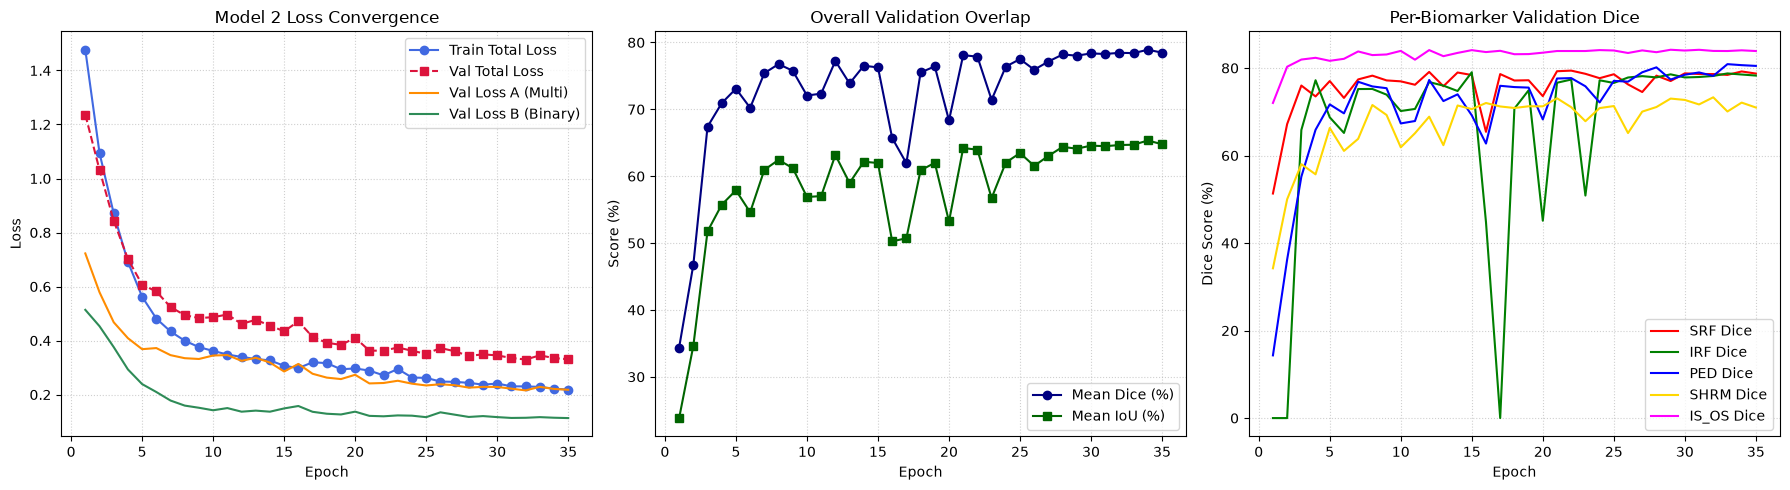

In [9]:
import pandas as pd

log_df = pd.read_csv("training_log_model2.csv")

fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Subplot 1: Loss progression
axs[0].plot(log_df["epoch"], log_df["train_total_loss"], 'o-', label="Train Total Loss", color="royalblue")
axs[0].plot(log_df["epoch"], log_df["val_total_loss"], 's--', label="Val Total Loss", color="crimson")
axs[0].plot(log_df["epoch"], log_df["val_loss_a"], label="Val Loss A (Multi)", color="darkorange")
axs[0].plot(log_df["epoch"], log_df["val_loss_b"], label="Val Loss B (Binary)", color="seagreen")
axs[0].set_title("Model 2 Loss Convergence")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()
axs[0].grid(True, linestyle=":", alpha=0.6)

# Subplot 2: Mean Dice & Mean IoU
axs[1].plot(log_df["epoch"], log_df["mean_dice"], 'o-', label="Mean Dice (%)", color="navy")
axs[1].plot(log_df["epoch"], log_df["mean_iou"], 's-', label="Mean IoU (%)", color="darkgreen")
axs[1].set_title("Overall Validation Overlap")
axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Score (%)")
axs[1].legend()
axs[1].grid(True, linestyle=":", alpha=0.6)

# Subplot 3: Per-biomarker Dice scores
lesions = ["SRF", "IRF", "PED", "SHRM", "IS_OS"]
colors = ["red", "green", "blue", "gold", "magenta"]
for lesion, c in zip(lesions, colors):
    axs[2].plot(log_df["epoch"], log_df[f"{lesion}_dice"], label=f"{lesion} Dice", color=c)
axs[2].set_title("Per-Biomarker Validation Dice")
axs[2].set_xlabel("Epoch")
axs[2].set_ylabel("Dice Score (%)")
axs[2].legend()
axs[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

## 7. Qualitative Visual Inspection: Stage 1 vs. Stage 2 Predictions
Loads the best trained checkpoint `best_unet_model2.pth` and visualizes:
1. Grayscale OCT B-scan input.
2. Ground-truth multi-class mask.
3. Stage 1 predicted binary foreground probability mask.
4. Stage 2 predicted 6-class lesion segmentation.

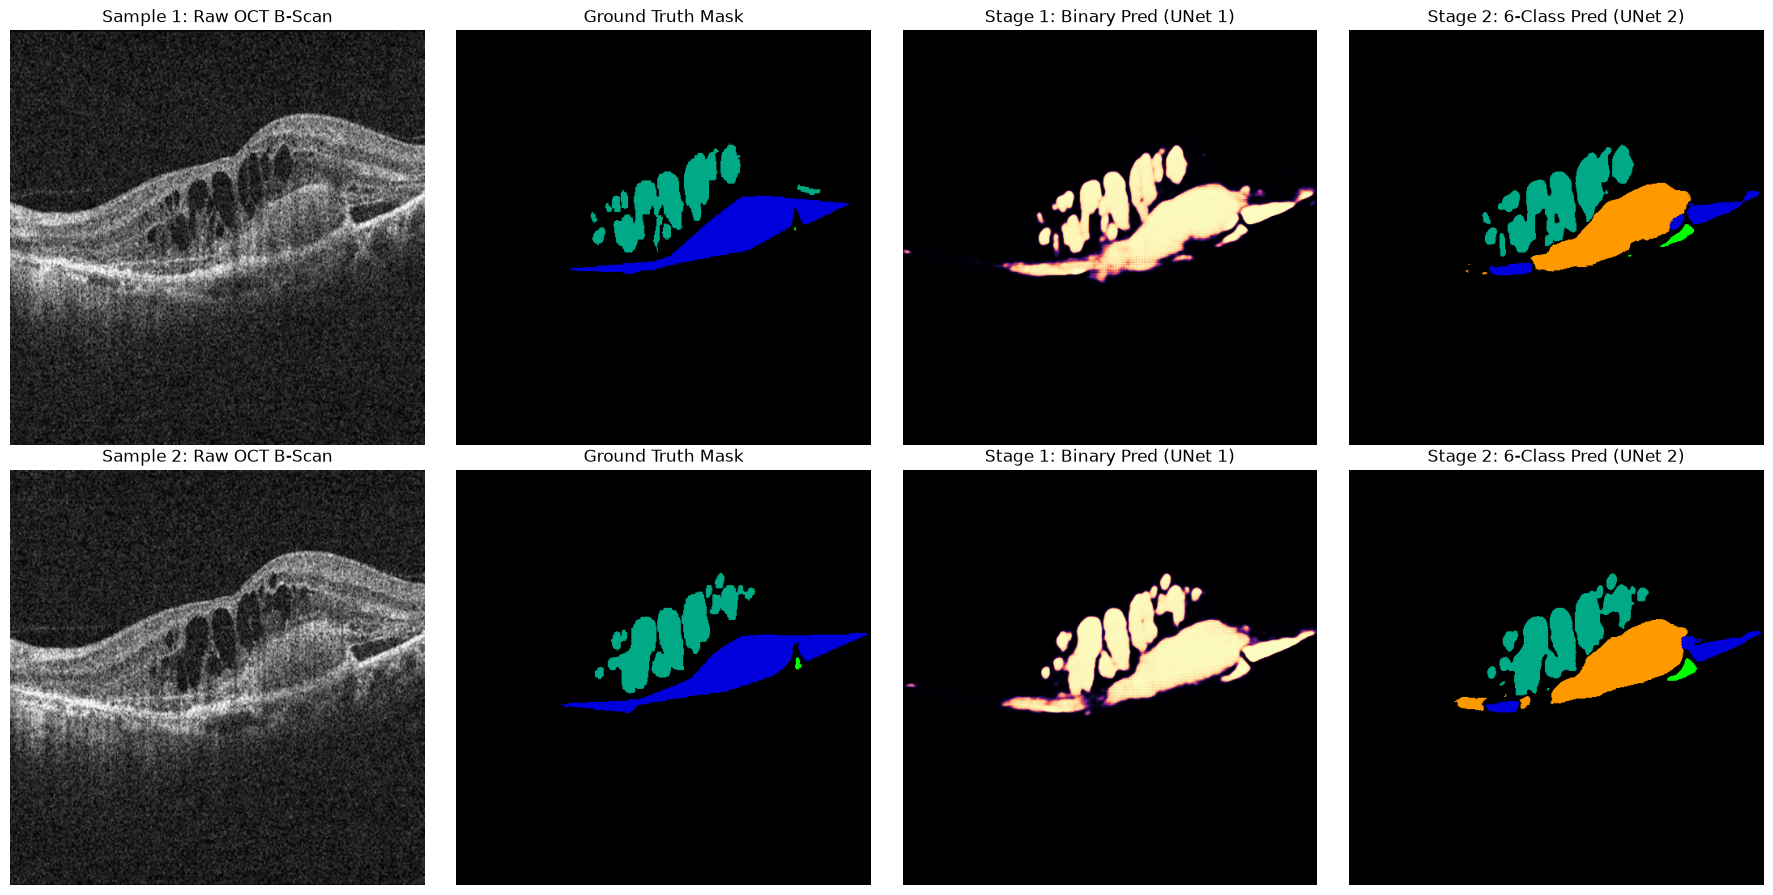

In [10]:
# Load optimal checkpoint
best_model2 = CascadedUNetModel2(in_channels=1, num_classes=6, base_channels=64, concatenate_input=False).to(device)
best_model2.load_state_dict(torch.load("best_unet_model2.pth", map_location=device))
best_model2.eval()

# Retrieve a sample validation batch
val_imgs, val_targets = next(iter(val_loader))
val_imgs = val_imgs.to(device)

with torch.no_grad():
    bin_logits, multi_logits = best_model2(val_imgs)
    bin_probs = torch.sigmoid(bin_logits).cpu().numpy()
    pred_classes = torch.argmax(multi_logits, dim=1).cpu().numpy()

# Plot first 2 samples
fig, axs = plt.subplots(2, 4, figsize=(18, 9))

for row in range(min(2, val_imgs.shape[0])):
    # 1. OCT input
    axs[row, 0].imshow(val_imgs[row, 0].cpu().numpy(), cmap='gray')
    axs[row, 0].set_title(f"Sample {row + 1}: Raw OCT B-Scan")
    axs[row, 0].axis("off")

    # 2. Ground Truth Mask
    axs[row, 1].imshow(val_targets[row].numpy(), cmap='nipy_spectral', vmin=0, vmax=5)
    axs[row, 1].set_title("Ground Truth Mask")
    axs[row, 1].axis("off")

    # 3. Stage 1 Binary Mask
    axs[row, 2].imshow(bin_probs[row, 0], cmap='magma', vmin=0.0, vmax=1.0)
    axs[row, 2].set_title("Stage 1: Binary Pred (UNet 1)")
    axs[row, 2].axis("off")

    # 4. Stage 2 Multi-Class Prediction
    axs[row, 3].imshow(pred_classes[row], cmap='nipy_spectral', vmin=0, vmax=5)
    axs[row, 3].set_title("Stage 2: 6-Class Pred (UNet 2)")
    axs[row, 3].axis("off")

plt.tight_layout()
plt.show()

## 8. Quantitative Model 2 Benchmark Evaluation Report
Evaluates the best-saved checkpoint (`best_unet_model2.pth`) against the 703 validation scans and compares per-biomarker performance directly against the official AMD-SD paper's Table 3 U-Net benchmark.

Loading Model 2 checkpoint from 'best_unet_model2.pth' on device: mps...


Evaluating Model 2 Benchmark: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [03:54<00:00,  1.50it/s]


             WET AMD LESION SEGMENTATION: MODEL 2 BENCHMARK REPORT


,Biomarker / Class,Paper U-Net Dice (%),Model 2 Dice (%),Dice Delta,Paper U-Net IoU (%),Model 2 IoU (%),IoU Delta
0,SRF,78.65%,79.22%,+0.57%,64.81%,65.59%,+0.78%
1,IRF,78.66%,78.52%,-0.14%,64.82%,64.63%,-0.19%
2,PED,79.62%,80.66%,+1.04%,66.14%,67.59%,+1.45%
3,SHRM,72.10%,72.10%,+0.00%,56.37%,56.38%,+0.01%
4,IS/OS,83.76%,84.05%,+0.29%,72.06%,72.48%,+0.42%
5,Mean (All Biomarkers),78.40%,78.91%,+0.51%,64.48%,65.34%,+0.86%


Report exported to 'model2_benchmark_report.csv'.


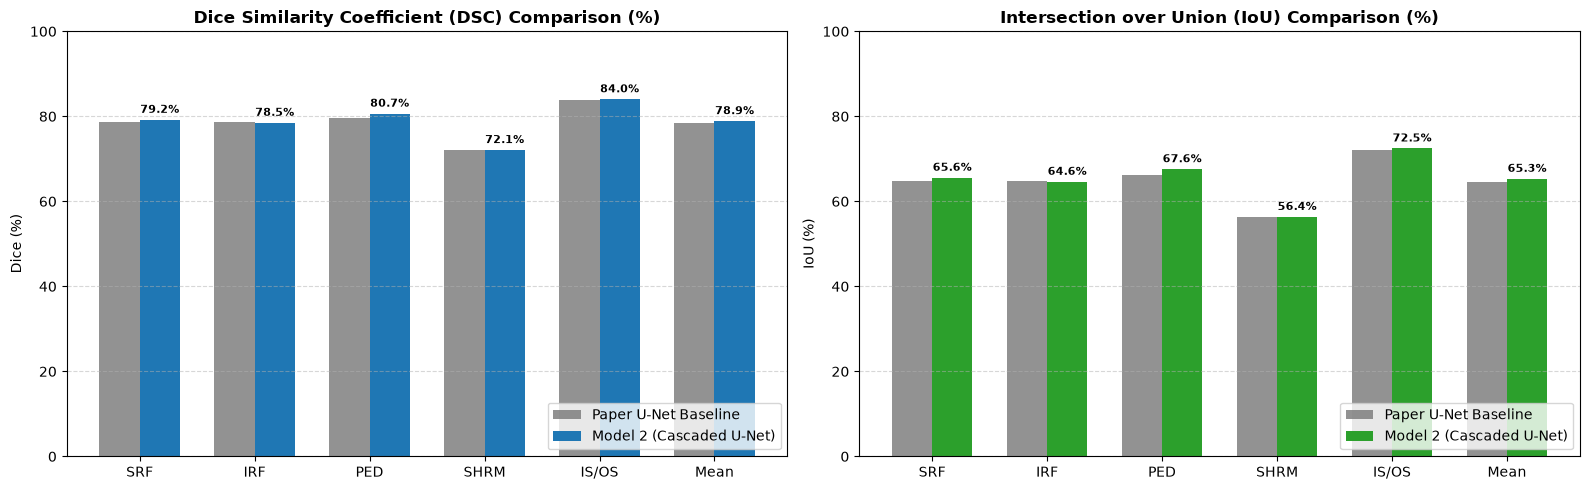

In [11]:
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

# Ensure device and memory cleanup
cleanup_memory()
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
CKPT_PATH = "best_unet_model2.pth"

# 1. Load optimal Model 2 checkpoint
print(f"Loading Model 2 checkpoint from '{CKPT_PATH}' on device: {device}...")
eval_model = CascadedUNetModel2(
    in_channels=1,
    num_classes=6,
    base_channels=64,
    concatenate_input=False
).to(device)

if not os.path.exists(CKPT_PATH):
    raise FileNotFoundError(f"Checkpoint '{CKPT_PATH}' not found. Please verify training completion.")

eval_model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
eval_model.eval()

# 2. Global Metric Accumulation on 703 Validation Scans
metric_tracker = GlobalMetricTracker(num_classes=6)

with torch.no_grad():
    for images, targets in tqdm(val_loader, desc="Evaluating Model 2 Benchmark"):
        images = images.to(device)
        targets = targets.to(device, dtype=torch.long)
        
        _, multi_logits = eval_model(images)
        preds = torch.argmax(multi_logits, dim=1)
        metric_tracker.update(preds, targets)

m2_dice, m2_iou, m2_mean_dice, m2_mean_iou = metric_tracker.compute()

# 3. Reference Values from AMD-SD Benchmark Literature (Table 3 Baseline U-Net)
paper_baseline_dice = {
    "SRF": 78.65,
    "IRF": 78.66,
    "PED": 79.62,
    "SHRM": 72.10,
    "IS/OS": 83.76,
    "Mean": 78.40
}

paper_baseline_iou = {
    "SRF": 64.81,
    "IRF": 64.82,
    "PED": 66.14,
    "SHRM": 56.37,
    "IS/OS": 72.06,
    "Mean": 64.48
}

# 4. Construct Benchmark Comparison Table
biomarkers = ["SRF", "IRF", "PED", "SHRM", "IS/OS"]
report_data = []

for b in biomarkers:
    report_data.append({
        "Biomarker / Class": b,
        "Paper U-Net Dice (%)": f"{paper_baseline_dice[b]:.2f}%",
        "Model 2 Dice (%)": f"{m2_dice[b]:.2f}%",
        "Dice Delta": f"{m2_dice[b] - paper_baseline_dice[b]:+.2f}%",
        "Paper U-Net IoU (%)": f"{paper_baseline_iou[b]:.2f}%",
        "Model 2 IoU (%)": f"{m2_iou[b]:.2f}%",
        "IoU Delta": f"{m2_iou[b] - paper_baseline_iou[b]:+.2f}%"
    })

# Add overall summary row
report_data.append({
    "Biomarker / Class": "Mean (All Biomarkers)",
    "Paper U-Net Dice (%)": f"{paper_baseline_dice['Mean']:.2f}%",
    "Model 2 Dice (%)": f"{m2_mean_dice:.2f}%",
    "Dice Delta": f"{m2_mean_dice - paper_baseline_dice['Mean']:+.2f}%",
    "Paper U-Net IoU (%)": f"{paper_baseline_iou['Mean']:.2f}%",
    "Model 2 IoU (%)": f"{m2_mean_iou:.2f}%",
    "IoU Delta": f"{m2_mean_iou - paper_baseline_iou['Mean']:+.2f}%"
})

benchmark_df = pd.DataFrame(report_data)

print("\n" + "="*80)
print("             WET AMD LESION SEGMENTATION: MODEL 2 BENCHMARK REPORT")
print("="*80)
display(benchmark_df)

# Export report to CSV
benchmark_df.to_csv("model2_benchmark_report.csv", index=False)
print("Report exported to 'model2_benchmark_report.csv'.")

# 5. Visual Comparison Chart
plot_categories = biomarkers + ["Mean"]
x = np.arange(len(plot_categories))
width = 0.35

m2_dices_plot = [m2_dice[b] for b in biomarkers] + [m2_mean_dice]
paper_dices_plot = [paper_baseline_dice[b] for b in plot_categories]

m2_ious_plot = [m2_iou[b] for b in biomarkers] + [m2_mean_iou]
paper_ious_plot = [paper_baseline_iou[b] for b in plot_categories]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Dice Score Plot
rects1 = ax1.bar(x - width/2, paper_dices_plot, width, label='Paper U-Net Baseline', color='#7f7f7f', alpha=0.85)
rects2 = ax1.bar(x + width/2, m2_dices_plot, width, label='Model 2 (Cascaded U-Net)', color='#1f77b4')
ax1.set_title('Dice Similarity Coefficient (DSC) Comparison (%)', fontweight='bold')
ax1.set_ylabel('Dice (%)')
ax1.set_xticks(x)
ax1.set_xticklabels(plot_categories)
ax1.set_ylim(0, 100)
ax1.legend(loc='lower right')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

# Annotate values
for bar in rects2:
    height = bar.get_height()
    ax1.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8, fontweight='bold')

# IoU Score Plot
rects3 = ax2.bar(x - width/2, paper_ious_plot, width, label='Paper U-Net Baseline', color='#7f7f7f', alpha=0.85)
rects4 = ax2.bar(x + width/2, m2_ious_plot, width, label='Model 2 (Cascaded U-Net)', color='#2ca02c')
ax2.set_title('Intersection over Union (IoU) Comparison (%)', fontweight='bold')
ax2.set_ylabel('IoU (%)')
ax2.set_xticks(x)
ax2.set_xticklabels(plot_categories)
ax2.set_ylim(0, 100)
ax2.legend(loc='lower right')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

for bar in rects4:
    height = bar.get_height()
    ax2.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points",
                ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.show()

cleanup_memory()

## 8. Statistical Evaluation & Per-Class Biomarker Distribution Analysis

Evaluates the saved model checkpoint on individual OCT B-scans to analyze variance, class-level difficulty, and statistical robustness:

1. **Per-Slice Metric Computation:** Calculates slice-level Dice and IoU scores across all 5 target biomarker classes (`SRF`, `IRF`, `PED`, `SHRM`, `IS/OS`). Slices where a biomarker is absent in both ground truth and prediction are assigned `NaN` to prevent skewing the evaluation.
2. **Empirical Bootstrapped 99% Confidence Intervals:** Runs non-parametric resampling with replacement ($N = 2{,}000$ iterations) to construct 99% confidence intervals ($\alpha = 0.01$) for mean Dice and IoU without assuming metric normality.
3. **Distribution Visualizations (Boxplots):** 
   - **Overall Slice Variance:** Boxplots showing the spread and mean (diamond marker) of per-image Dice and IoU.
   - **Biomarker Breakdown:** Class-stratified boxplots highlighting which anatomical lesions benefit most from the architectural design choices.

Loaded weights from best_unet_model2.pth into Model 2 successfully.
Evaluating on 703 validation pairs.


Evaluating Model 2 (Cascaded U-Net): 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 352/352 [04:01<00:00,  1.46it/s]


,0
Model,Model 2 (Cascaded U-Net)
Mean Dice [%] (99% CI),"64.15 [61.87, 66.39]"
Mean IoU [%] (99% CI),"55.15 [53.12, 57.21]"
SRF Dice [%],"62.90 [58.48, 67.14]"
SRF IoU [%],"54.85 [50.64, 58.83]"
IRF Dice [%],"51.11 [43.74, 57.54]"
IRF IoU [%],"43.26 [36.50, 49.40]"
PED Dice [%],"55.58 [51.31, 59.51]"
PED IoU [%],"46.82 [42.97, 50.39]"
SHRM Dice [%],"54.64 [50.46, 58.91]"


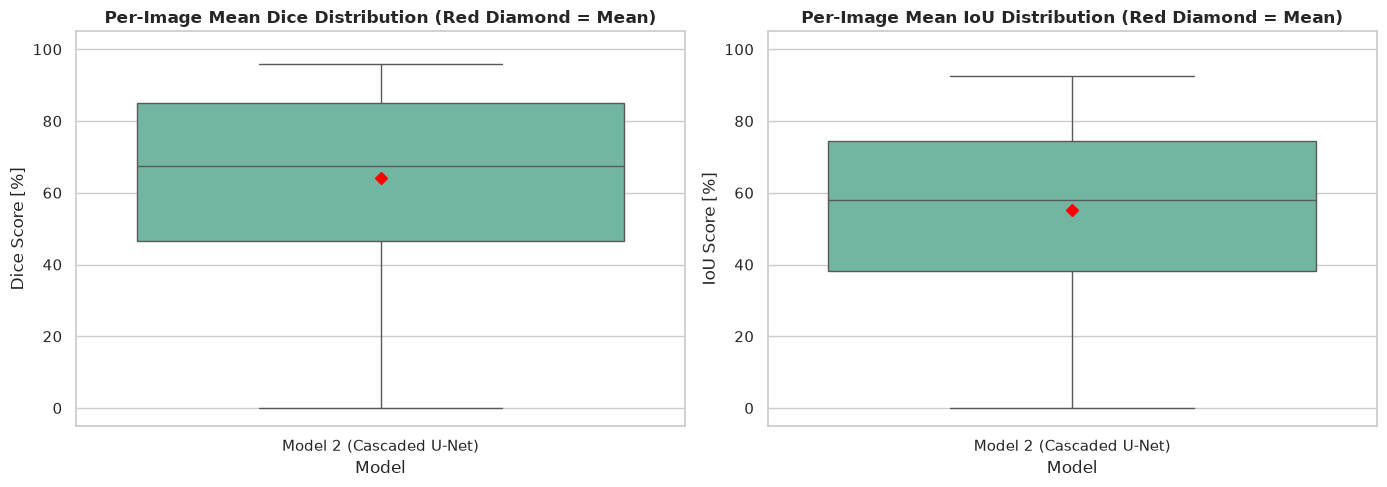

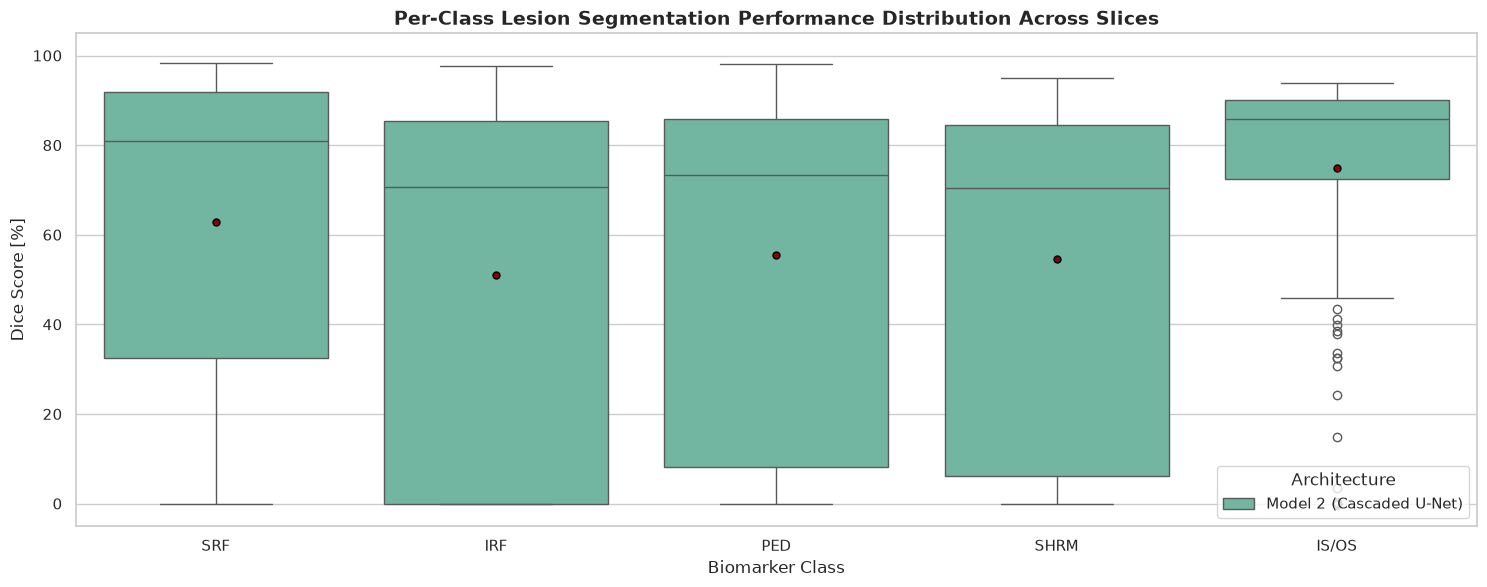

In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import DataLoader
from tqdm import tqdm

# --- 1. Load Trained Checkpoint ---
CKPT_PATH = "best_unet_model2.pth"

model_2 = CascadedUNetModel2(
    in_channels=1,
    num_classes=6,
    base_channels=64,
    concatenate_input=False
).to(device)

checkpoint = torch.load(CKPT_PATH, map_location=device)
model_2.load_state_dict(checkpoint)
model_2.eval()
print(f"Loaded weights from {CKPT_PATH} into Model 2 successfully.")

# Setup test/eval loader
if "test_loader" in globals():
    eval_loader = test_loader
    print("Evaluating on test_loader.")
elif os.path.exists(os.path.join(DATA_DIR, "test")):
    test_dataset = AMDDataset(DATA_DIR, split="test", target_size=(512, 512), augment=False)
    eval_loader = DataLoader(
        test_dataset,
        batch_size=VAL_BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(device.type == "cuda")
    )
    print(f"Loaded {len(test_dataset)} test pairs.")
else:
    eval_loader = val_loader
    print(f"Evaluating on {len(val_dataset)} validation pairs.")


# --- 2. Metric Calculation Helpers ---
def compute_image_metrics(pred_mask: np.ndarray, target_mask: np.ndarray):
    class_map = {1: "SRF", 2: "IRF", 3: "PED", 4: "SHRM", 5: "IS/OS"}
    dice_scores = {}
    iou_scores = {}

    for c_idx, c_name in class_map.items():
        p = (pred_mask == c_idx)
        t = (target_mask == c_idx)
        p_sum, t_sum = p.sum(), t.sum()
        intersection = np.logical_and(p, t).sum()
        union = np.logical_or(p, t).sum()

        if t_sum == 0 and p_sum == 0:
            dice_scores[c_name] = np.nan
            iou_scores[c_name] = np.nan
        else:
            dice = (2.0 * intersection) / (p_sum + t_sum + 1e-8) * 100.0
            iou = intersection / (union + 1e-8) * 100.0
            dice_scores[c_name] = dice
            iou_scores[c_name] = iou

    valid_dices = [v for v in dice_scores.values() if not np.isnan(v)]
    valid_ious = [v for v in iou_scores.values() if not np.isnan(v)]

    mean_dice = np.mean(valid_dices) if len(valid_dices) > 0 else np.nan
    mean_iou = np.mean(valid_ious) if len(valid_ious) > 0 else np.nan

    return dice_scores, iou_scores, mean_dice, mean_iou


def bootstrap_ci(data: np.ndarray, n_bootstraps: int = 2000, ci: float = 0.99):
    clean_data = data[~np.isnan(data)]
    if len(clean_data) == 0:
        return np.nan, (np.nan, np.nan)

    n = len(clean_data)
    boot_means = np.empty(n_bootstraps)
    for i in range(n_bootstraps):
        sample = np.random.choice(clean_data, size=n, replace=True)
        boot_means[i] = np.mean(sample)

    alpha = (1.0 - ci) / 2.0
    ci_lower = np.percentile(boot_means, alpha * 100.0)
    ci_upper = np.percentile(boot_means, (1.0 - alpha) * 100.0)
    return float(np.mean(clean_data)), (float(ci_lower), float(ci_upper))


# --- 3. Evaluate Models ---
models_to_evaluate = {
    "Model 2 (Cascaded U-Net)": model_2
}

per_image_records = []
lesions = ["SRF", "IRF", "PED", "SHRM", "IS/OS"]

for model_name, net in models_to_evaluate.items():
    net.eval()
    img_counter = 0

    with torch.no_grad():
        for images, targets in tqdm(eval_loader, desc=f"Evaluating {model_name}"):
            images = images.to(device)
            targets = targets.cpu().numpy()

            outputs = net(images)
            multi_logits = outputs[1] if isinstance(outputs, tuple) else outputs
            preds = torch.argmax(multi_logits, dim=1).cpu().numpy()

            batch_size = images.size(0)
            for b in range(batch_size):
                p_img = preds[b]
                t_img = targets[b]

                d_scores, i_scores, m_dice, m_iou = compute_image_metrics(p_img, t_img)

                record = {
                    "Model": model_name,
                    "Image_ID": img_counter,
                    "Mean_Dice": m_dice,
                    "Mean_IoU": m_iou,
                }
                for l in lesions:
                    record[f"{l}_Dice"] = d_scores[l]
                    record[f"{l}_IoU"] = i_scores[l]

                per_image_records.append(record)
                img_counter += 1

df_results = pd.DataFrame(per_image_records)


# --- 4. 99% Bootstrapped Confidence Interval Summary ---
summary_rows = []
for model_name in models_to_evaluate.keys():
    sub_df = df_results[df_results["Model"] == model_name]

    m_dice, (d_low, d_high) = bootstrap_ci(sub_df["Mean_Dice"].values, n_bootstraps=2000, ci=0.99)
    m_iou, (i_low, i_high) = bootstrap_ci(sub_df["Mean_IoU"].values, n_bootstraps=2000, ci=0.99)

    row = {
        "Model": model_name,
        "Mean Dice [%] (99% CI)": f"{m_dice:.2f} [{d_low:.2f}, {d_high:.2f}]",
        "Mean IoU [%] (99% CI)": f"{m_iou:.2f} [{i_low:.2f}, {i_high:.2f}]",
    }

    for l in lesions:
        l_dice, (ld_low, ld_high) = bootstrap_ci(sub_df[f"{l}_Dice"].values, n_bootstraps=2000, ci=0.99)
        l_iou, (li_low, li_high) = bootstrap_ci(sub_df[f"{l}_IoU"].values, n_bootstraps=2000, ci=0.99)
        row[f"{l} Dice [%]"] = f"{l_dice:.2f} [{ld_low:.2f}, {ld_high:.2f}]"
        row[f"{l} IoU [%]"] = f"{l_iou:.2f} [{li_low:.2f}, {li_high:.2f}]"

    summary_rows.append(row)

df_bootstrap_summary = pd.DataFrame(summary_rows)
display(df_bootstrap_summary.T)


# --- 5. Boxplots ---
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams.update({"font.sans-serif": "DejaVu Sans", "font.size": 11})

# Overall Mean Metrics
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df_results, x="Model", y="Mean_Dice", ax=axes[0],
    showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "red"}
)
axes[0].set_title("Per-Image Mean Dice Distribution (Red Diamond = Mean)", fontweight="bold")
axes[0].set_ylabel("Dice Score [%]")
axes[0].set_ylim(-5, 105)

sns.boxplot(
    data=df_results, x="Model", y="Mean_IoU", ax=axes[1],
    showmeans=True, meanprops={"marker": "D", "markerfacecolor": "red", "markeredgecolor": "red"}
)
axes[1].set_title("Per-Image Mean IoU Distribution (Red Diamond = Mean)", fontweight="bold")
axes[1].set_ylabel("IoU Score [%]")
axes[1].set_ylim(-5, 105)

plt.tight_layout()
plt.show()

# Per-Class Lesion Breakdown Across Slices
dice_cols = [f"{l}_Dice" for l in lesions]
df_melted_dice = pd.melt(
    df_results,
    id_vars=["Model", "Image_ID"],
    value_vars=dice_cols,
    var_name="Lesion_Class",
    value_name="Dice_Score"
).dropna()

df_melted_dice["Lesion_Class"] = df_melted_dice["Lesion_Class"].apply(lambda name: name.replace("_Dice", ""))

plt.figure(figsize=(15, 6))
sns.boxplot(
    data=df_melted_dice,
    x="Lesion_Class",
    y="Dice_Score",
    hue="Model",
    showmeans=True,
    meanprops={"marker": "o", "markerfacecolor": "darkred", "markeredgecolor": "black", "markersize": 5}
)
plt.title("Per-Class Lesion Segmentation Performance Distribution Across Slices", fontsize=14, fontweight="bold")
plt.xlabel("Biomarker Class", fontsize=12)
plt.ylabel("Dice Score [%]", fontsize=12)
plt.ylim(-5, 105)
plt.legend(title="Architecture", loc="lower right", frameon=True)
plt.tight_layout()
plt.show()